## Gridding SMAP to 0.1 x 0.1 degree resolution 


In [1]:
import pandas as pd
import numpy as np 
import xarray as xr 
import xesmf as xe
 

### SMAP 
Gridding SMAP up to 0.1 x 0.1 degree resolution, it was originally at 9km x 9km resolution

In [2]:
WFPS_file = '/global/scratch/users/toireasamarie/SMAP/midwest_soil_moisture_poros_WFPS.parquet'
smap_df=pd.read_parquet(WFPS_file, engine='pyarrow')

In [3]:
smap_df.head()

,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime_x,catchment_model_porosity,microwave_model_porosity,diff_c-m,WFPS_c,WFPS_m,WFPS_diff
0,48.951267,-103.957474,0.087287,0.119180,282.964539,273.160004,0.042725,2024-02-29 22:28:55,0.3963,0.4351,-0.0388,0.220254,0.200613,0.019641
1,48.951267,-103.864113,0.158729,0.200062,282.894318,273.160004,0.036697,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.364726,0.346267,0.018459
2,48.951267,-103.770752,0.160134,0.201959,282.958588,273.160004,0.030681,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.367954,0.349332,0.018622
3,48.951267,-103.677391,0.159644,0.203763,282.922485,273.160004,0.029179,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366829,0.348264,0.018566
4,48.951267,-103.584030,0.159519,0.203495,282.843567,273.160004,0.029720,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.366541,0.347990,0.018551


In [4]:
smap_reduced_df = smap_df.drop(columns={'microwave_model_porosity', 'diff_c-m','WFPS_m', 'WFPS_diff'})
smap_reduced_df=smap_reduced_df.rename(columns ={'datetime_x':'datetime'})
smap_reduced_df.head()

,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime,catchment_model_porosity,WFPS_c
0,48.951267,-103.957474,0.087287,0.119180,282.964539,273.160004,0.042725,2024-02-29 22:28:55,0.3963,0.220254
1,48.951267,-103.864113,0.158729,0.200062,282.894318,273.160004,0.036697,2024-02-29 22:28:55,0.4352,0.364726
2,48.951267,-103.770752,0.160134,0.201959,282.958588,273.160004,0.030681,2024-02-29 22:28:55,0.4352,0.367954
3,48.951267,-103.677391,0.159644,0.203763,282.922485,273.160004,0.029179,2024-02-29 22:28:55,0.4352,0.366829
4,48.951267,-103.584030,0.159519,0.203495,282.843567,273.160004,0.029720,2024-02-29 22:28:55,0.4352,0.366541


In [5]:
smap_reduced_df['datetime'].unique()

<DatetimeArray>
['2024-02-29 22:28:55', '2024-03-01 01:28:55', '2024-03-01 04:28:55',
 '2024-03-01 07:28:55', '2024-03-01 10:28:55', '2024-03-01 13:28:55',
 '2024-03-01 16:28:55', '2024-03-01 19:28:55', '2024-03-01 22:28:55',
 '2024-03-02 01:28:55',
 ...
 '2024-07-30 19:28:55', '2024-07-30 22:28:55', '2024-07-31 01:28:55',
 '2024-07-31 04:28:55', '2024-07-31 07:28:55', '2024-07-31 10:28:55',
 '2024-07-31 13:28:55', '2024-07-31 16:28:55', '2024-07-31 19:28:55',
 '2024-07-31 22:28:55']
Length: 1225, dtype: datetime64[ns]

In [6]:
regridding_df=smap_reduced_df.copy()

In [7]:
regridding_df['lat'] = regridding_df['latitude'].round(5)
regridding_df['lon'] = regridding_df['longitude'].round(5)

#converting to xarray
ds = regridding_df.set_index(['datetime', 'lat', 'lon']).to_xarray()

#will give dataset with no2 as variable and dimensions of time lat lon  
da = ds[['sm_surface', 'surface_temp', 'soil_temp_layer1', 'LAI','catchment_model_porosity', 'WFPS_c']]

In [8]:
da

<xarray.Dataset> Size: 1GB
Dimensions:                   (datetime: 1225, lat: 136, lon: 257)
Coordinates:
  * datetime                  (datetime) datetime64[ns] 10kB 2024-02-29T22:28...
  * lat                       (lat) float32 544B 36.07 36.16 ... 48.84 48.95
  * lon                       (lon) float32 1kB -104.0 -103.9 ... -80.15 -80.06
Data variables:
    sm_surface                (datetime, lat, lon) float32 171MB 0.1539 ... 0...
    surface_temp              (datetime, lat, lon) float32 171MB 288.5 ... 300.1
    soil_temp_layer1          (datetime, lat, lon) float32 171MB 282.3 ... 297.9
    LAI                       (datetime, lat, lon) float32 171MB 0.184 ... 3.405
    catchment_model_porosity  (datetime, lat, lon) float32 171MB 0.4181 ... 0...
    WFPS_c                    (datetime, lat, lon) float32 171MB 0.3681 ... 0...

In [9]:
#input grid (lat/lon already in the DataArray)
ds_in = xr.Dataset({'lat': (['lat'], da.lat.values), 'lon': (['lon'], da.lon.values)})

#define output 0.1° x 0.1° grid
lat_out = np.arange(36.05, 49.0, 0.1)   #36.05, 36.15, ..., 48.95 as centers of grids 
lon_out = np.arange(-103.95, -80, 0.1)  #-103.95, -103.85, ..., -80.05 as centers of grids 

ds_out = xr.Dataset({'lat': (['lat'], lat_out), 'lon': (['lon'], lon_out)})

In [10]:
#creating regridder
regridder = xe.Regridder(ds_in, ds_out, 'conservative')
regridder

xESMF Regridder 
Regridding algorithm:       conservative 
Weight filename:            conservative_136x257_130x240.nc 
Reuse pre-computed weights? False 
Input grid shape:           (136, 257) 
Output grid shape:          (130, 240) 
Periodic in longitude?      False

In [11]:
da_out = regridder(da, keep_attrs=True)

In [12]:
da_out

<xarray.Dataset> Size: 917MB
Dimensions:                   (datetime: 1225, lat: 130, lon: 240)
Coordinates:
  * datetime                  (datetime) datetime64[ns] 10kB 2024-02-29T22:28...
  * lat                       (lat) float64 1kB 36.05 36.15 ... 48.85 48.95
  * lon                       (lon) float64 2kB -104.0 -103.9 ... -80.15 -80.05
Data variables:
    sm_surface                (datetime, lat, lon) float32 153MB 0.1147 ... 0...
    surface_temp              (datetime, lat, lon) float32 153MB 209.3 ... 268.9
    soil_temp_layer1          (datetime, lat, lon) float32 153MB 204.8 ... 267.0
    LAI                       (datetime, lat, lon) float32 153MB 0.1331 ... 3...
    catchment_model_porosity  (datetime, lat, lon) float32 153MB 0.3056 ... 0...
    WFPS_c                    (datetime, lat, lon) float32 153MB 0.272 ... 0....
Attributes:
    regrid_method:  conservative

## Plots of original data vs regridded data for each variable:

In [13]:
import matplotlib.pyplot as plt


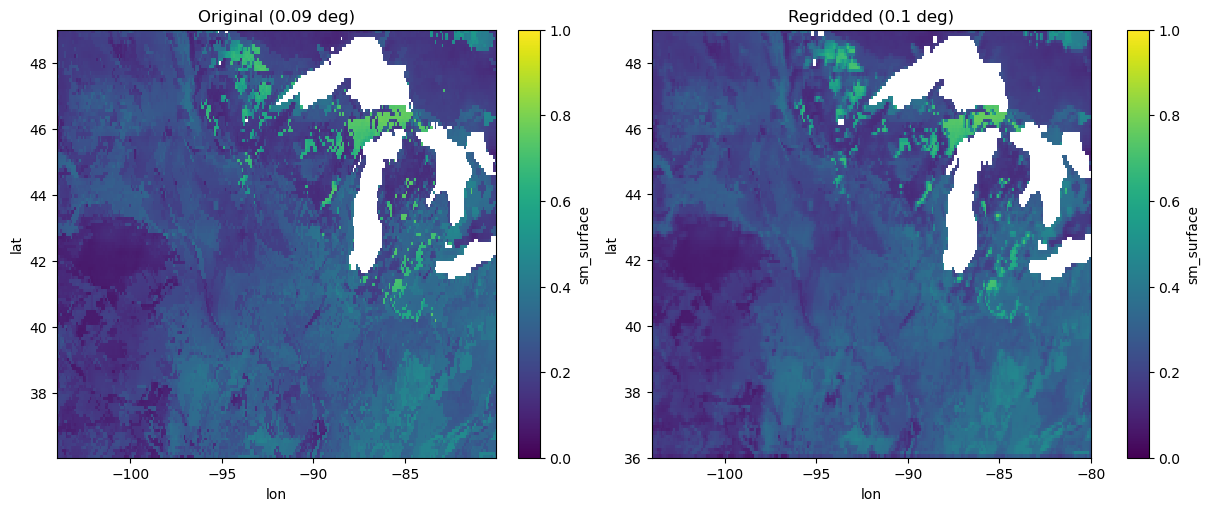

In [14]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['sm_surface'].isel(datetime=0).plot(ax=axes[0], vmin=0, vmax=1)
axes[0].set_title("Original (0.09 deg)")

da_out['sm_surface'].isel(datetime=0).plot(ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()

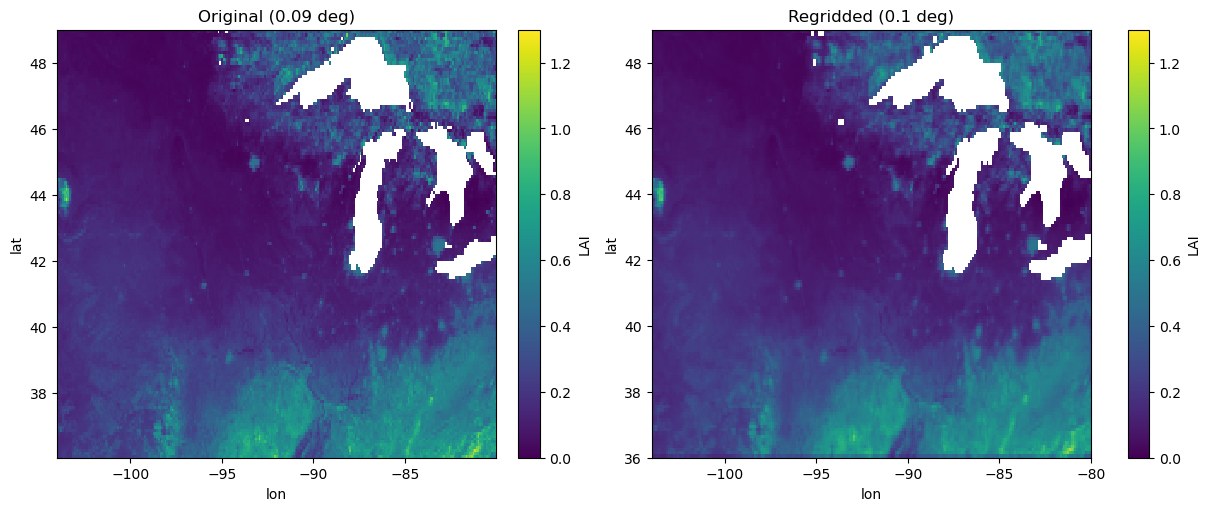

In [15]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['LAI'].isel(datetime=0).plot(ax=axes[0], vmin=0, vmax=1.3)
axes[0].set_title("Original (0.09 deg)")

da_out['LAI'].isel(datetime=0).plot(ax=axes[1], vmin=0, vmax=1.3)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()



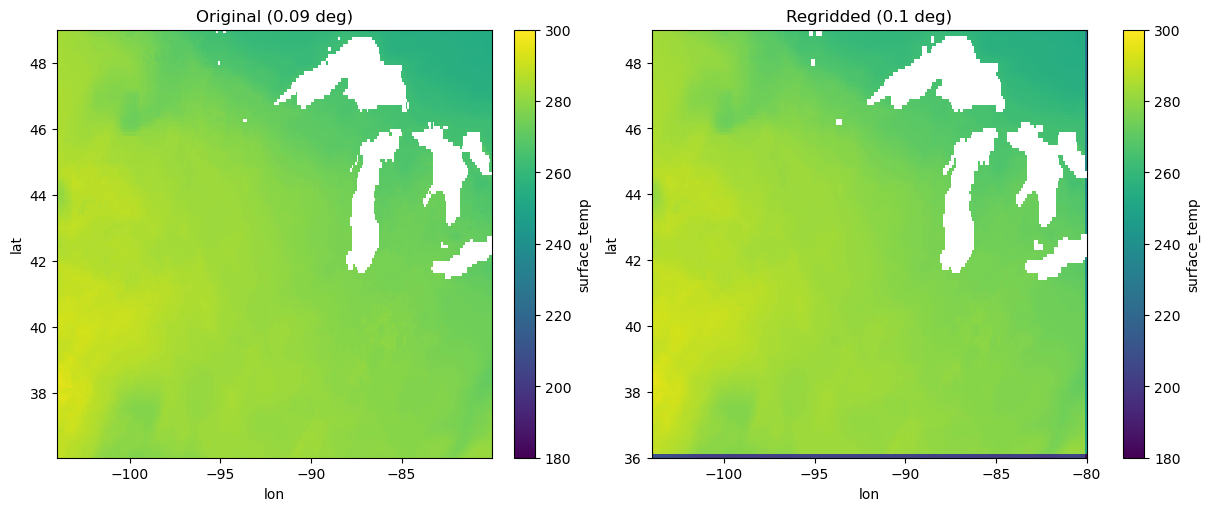

In [16]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['surface_temp'].isel(datetime=0).plot(ax=axes[0], vmin=180, vmax=300)
axes[0].set_title("Original (0.09 deg)")

da_out['surface_temp'].isel(datetime=0).plot(ax=axes[1], vmin=180, vmax=300)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()



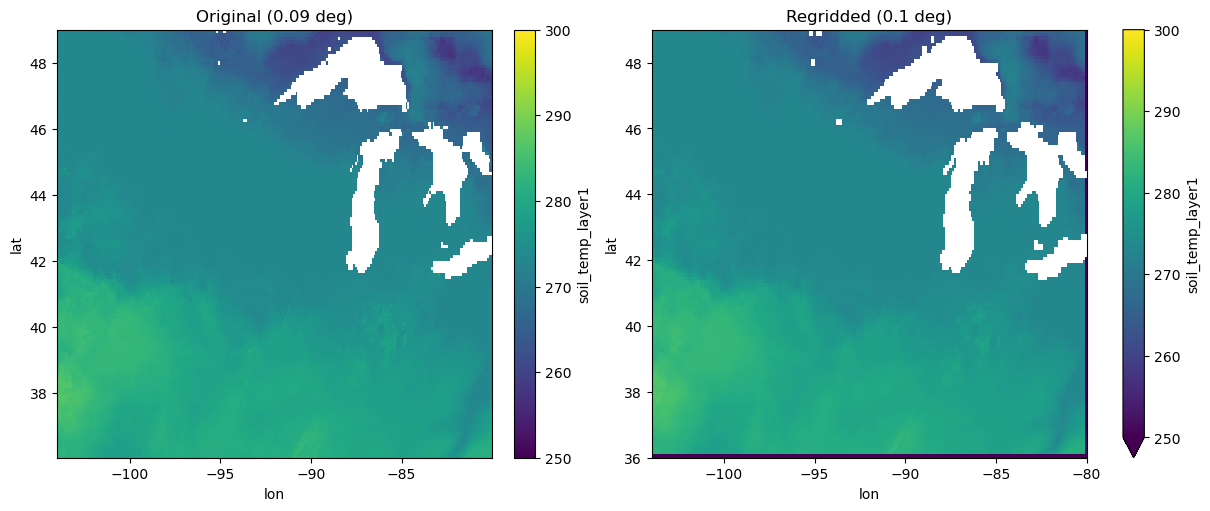

In [17]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['soil_temp_layer1'].isel(datetime=0).plot(ax=axes[0], vmin=250, vmax=300)
axes[0].set_title("Original (0.09 deg)")

da_out['soil_temp_layer1'].isel(datetime=0).plot(ax=axes[1], vmin=250, vmax=300)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()

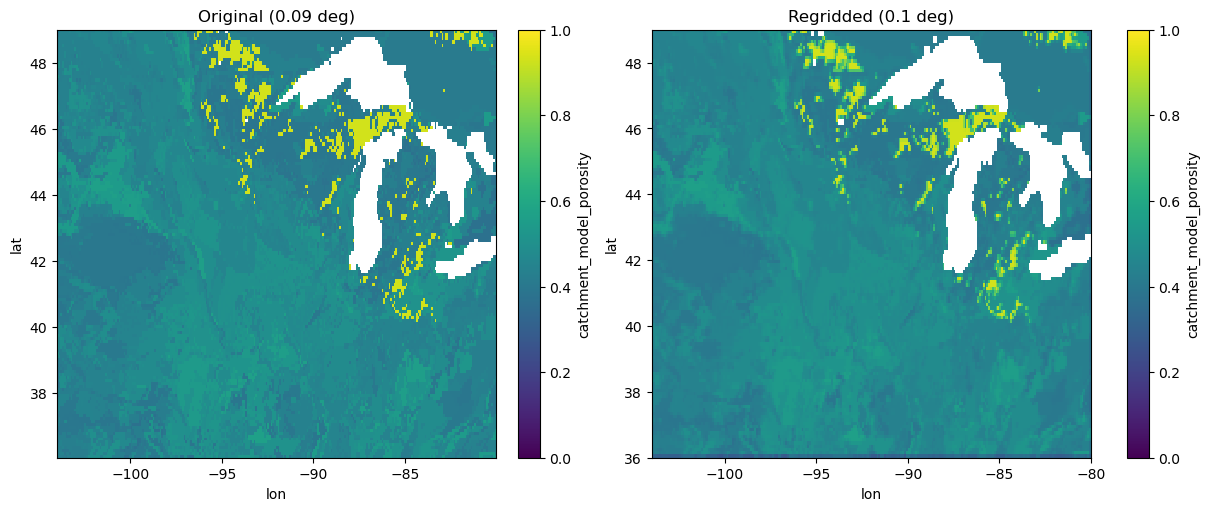

In [18]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['catchment_model_porosity'].isel(datetime=0).plot(ax=axes[0], vmin=0, vmax=1)
axes[0].set_title("Original (0.09 deg)")

da_out['catchment_model_porosity'].isel(datetime=0).plot(ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()


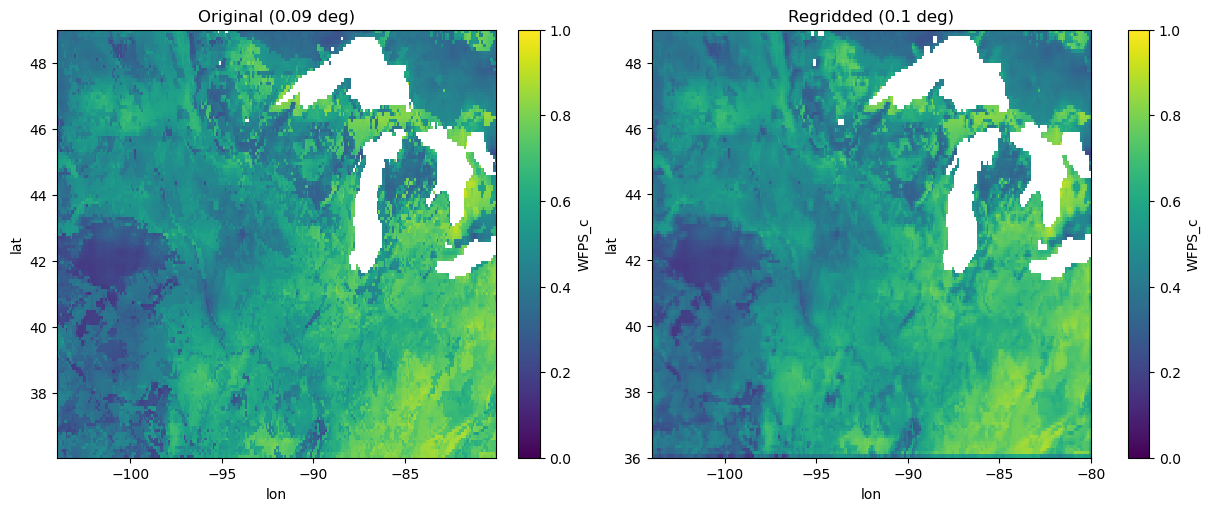

In [19]:
fig, axes = plt.subplots(ncols=2, figsize=(12, 5), constrained_layout=True)

da['WFPS_c'].isel(datetime=0).plot(ax=axes[0], vmin=0, vmax=1)
axes[0].set_title("Original (0.09 deg)")

da_out['WFPS_c'].isel(datetime=0).plot(ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Regridded (0.1 deg)")

plt.show()

## Extracting regridded data as a dataframe --> parquet file

In [20]:
df_regridded = da_out.to_dataframe().reset_index()

In [21]:
{'sm_surface', 'surface_temp','soil_temp_layer1','LAI', 'catchment_model_porosity','WFPS_c'}

{'LAI',
 'WFPS_c',
 'catchment_model_porosity',
 'sm_surface',
 'soil_temp_layer1',
 'surface_temp'}

In [22]:
df_regridded

,datetime,lat,lon,sm_surface,surface_temp,soil_temp_layer1,LAI,catchment_model_porosity,WFPS_c
0,2024-02-29 22:28:55,36.05,-103.95,0.114719,209.289124,204.827133,0.133121,0.305608,0.272029
1,2024-02-29 22:28:55,36.05,-103.85,0.136838,209.268600,204.792053,0.131916,0.322000,0.308128
2,2024-02-29 22:28:55,36.05,-103.75,0.119576,209.228104,204.874603,0.145216,0.308726,0.280935
3,2024-02-29 22:28:55,36.05,-103.65,0.106267,209.052612,204.841431,0.156914,0.303328,0.254167
4,2024-02-29 22:28:55,36.05,-103.55,0.092758,208.658096,204.652618,0.149581,0.297745,0.226232
...,...,...,...,...,...,...,...,...,...
38219995,2024-07-31 22:28:55,48.95,-80.45,0.312607,299.696136,297.286926,3.231004,0.545900,0.572645
38219996,2024-07-31 22:28:55,48.95,-80.35,0.160308,300.061981,297.882446,3.293951,0.401898,0.386233
38219997,2024-07-31 22:28:55,48.95,-80.25,0.123584,300.108307,297.992554,3.220209,0.374100,0.330351
38219998,2024-07-31 22:28:55,48.95,-80.15,0.115252,300.174438,297.945709,3.664636,0.374100,0.308078


In [23]:
df_regridded.to_parquet('/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/SMAP_LAI_WFPS_0.1x0.1gridded_mar-jul.parquet',
                        engine='pyarrow')

In [25]:
grid_lon_sorted = np.sort(df_regridded['lon'].unique())
grid_lon_diff = np.diff(grid_lon_sorted)
print(np.unique(np.round(grid_lon_diff, 4)))


[0.1]
